# 🌍 Multilingual Natural Language Inference (NLI)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hataminahid/multilingual-nli-xlm-roberta/blob/main/notebooks/multilingual_nli_xlm_roberta.ipynb)

Kaggle *Contradictory, My Dear Watson* — classify premise/hypothesis pairs in 15 languages as **entailment / neutral / contradiction**.
**Phase I:** EDA & feature engineering → **Phase II:** fine-tuned XLM-RoBERTa → **Phase III:** traditional ML baselines & comparison.

> Run the *Setup* cell first. Use a **GPU runtime** (Runtime → Change runtime type → T4) for Phase II.

---
#  Practical Assignment: Multilingual Natural Language Inference (NLI)
---

In [ ]:
# ============================ Setup (local + Colab) ============================
import os, sys, glob, shutil, zipfile, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # packages Colab does not ship with (torch / transformers / sklearn are preinstalled)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "missingno", "xgboost"], check=True)

os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# The Kaggle data is not stored in the repo. Expected files: data/train.csv, data/test.csv, data/sample_submission.csv
if not os.path.exists("data/train.csv"):
    if IN_COLAB:
        from google.colab import files
        print("Upload the Kaggle zip 'contradictory-my-dear-watson.zip' (or train.csv / test.csv / sample_submission.csv)")
        for name in files.upload():
            if name.endswith(".zip"):
                zipfile.ZipFile(name).extractall("data")
            elif name.endswith(".csv"):
                shutil.move(name, os.path.join("data", name))
    else:
        raise FileNotFoundError(
            "Download the data from https://www.kaggle.com/competitions/contradictory-my-dear-watson/data "
            "and extract train.csv, test.csv, sample_submission.csv into the data/ folder.")
print("data/ contains:", sorted(os.listdir("data")))


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import os, re, unicodedata, warnings
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup,)
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, roc_auc_score, roc_curve, auc,
    precision_score, recall_score, precision_recall_curve,)
from sklearn.linear_model    import LogisticRegression
from sklearn.ensemble        import RandomForestClassifier
from sklearn.svm             import LinearSVC
from sklearn.calibration     import CalibratedClassifierCV
from sklearn.preprocessing   import StandardScaler
from sklearn.pipeline        import Pipeline
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from xgboost import XGBClassifier


In [ ]:
train_df = pd.read_csv('./data/train.csv')
test_df = pd.read_csv('./data/test.csv')
sample_submission = pd.read_csv('./data/sample_submission.csv')


In [4]:
display(train_df.head())

,id,premise,hypothesis,lang_abv,language,label
0,5130fd2cb5,and these comments were considered in formulat...,The rules developed in the interim were put to...,en,English,0
1,5b72532a0b,These are issues that we wrestle with in pract...,Practice groups are not permitted to work on t...,en,English,2
2,3931fbe82a,Des petites choses comme celles-là font une di...,J'essayais d'accomplir quelque chose.,fr,French,0
3,5622f0c60b,you know they can't really defend themselves l...,They can't defend themselves because of their ...,en,English,0
4,86aaa48b45,ในการเล่นบทบาทสมมุติก็เช่นกัน โอกาสที่จะได้แสด...,เด็กสามารถเห็นได้ว่าชาติพันธุ์แตกต่างกันอย่างไร,th,Thai,1


In [6]:
sns.set_theme(style="whitegrid", font_scale=1.1)


In [7]:
print("\n -------------------------------------")
print("train shape:", train_df.shape)
print("test shape:", test_df.shape)
print("sample_submission shape:", sample_submission.shape)

print("\n -------------------------------------")
print("\n train_columns:", train_df.columns.tolist())
print("\n test_columns:", test_df.columns.tolist())
print(f'sample_submission_columns: {sample_submission.columns.tolist()}')

print("\n -------------------------------------")

print("\n missing values:\n", train_df.isnull().sum())
print("\n -------------------------------------")
print("\n train_df :\n", train_df.info())




 -------------------------------------
train shape: (12120, 6)
test shape: (5195, 5)
sample_submission shape: (5195, 2)

 -------------------------------------

 train_columns: ['id', 'premise', 'hypothesis', 'lang_abv', 'language', 'label']

 test_columns: ['id', 'premise', 'hypothesis', 'lang_abv', 'language']
sample_submission_columns: ['id', 'prediction']

 -------------------------------------

 missing values:
 id            0
premise       0
hypothesis    0
lang_abv      0
language      0
label         0
dtype: int64

 -------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12120 entries, 0 to 12119
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          12120 non-null  object
 1   premise     12120 non-null  object
 2   hypothesis  12120 non-null  object
 3   lang_abv    12120 non-null  object
 4   language    12120 non-null  object
 5   label       12120 non-null  int64 
d

This dataset is a natural language processing dataset that contains 12,120 records in the training set and 5,195 records in the test set. As observed, there are no missing values in the columns. However, considering the given task, the data distribution has also been visualized for further inspection.
The training dataset includes 6 features, while the test dataset contains 5 features (without labels). Additionally, the sample_submission_columns section includes two features.

Phase I: Exploratory Data Analysis (EDA) and Feature Engineering

<Figure size 800x400 with 0 Axes>

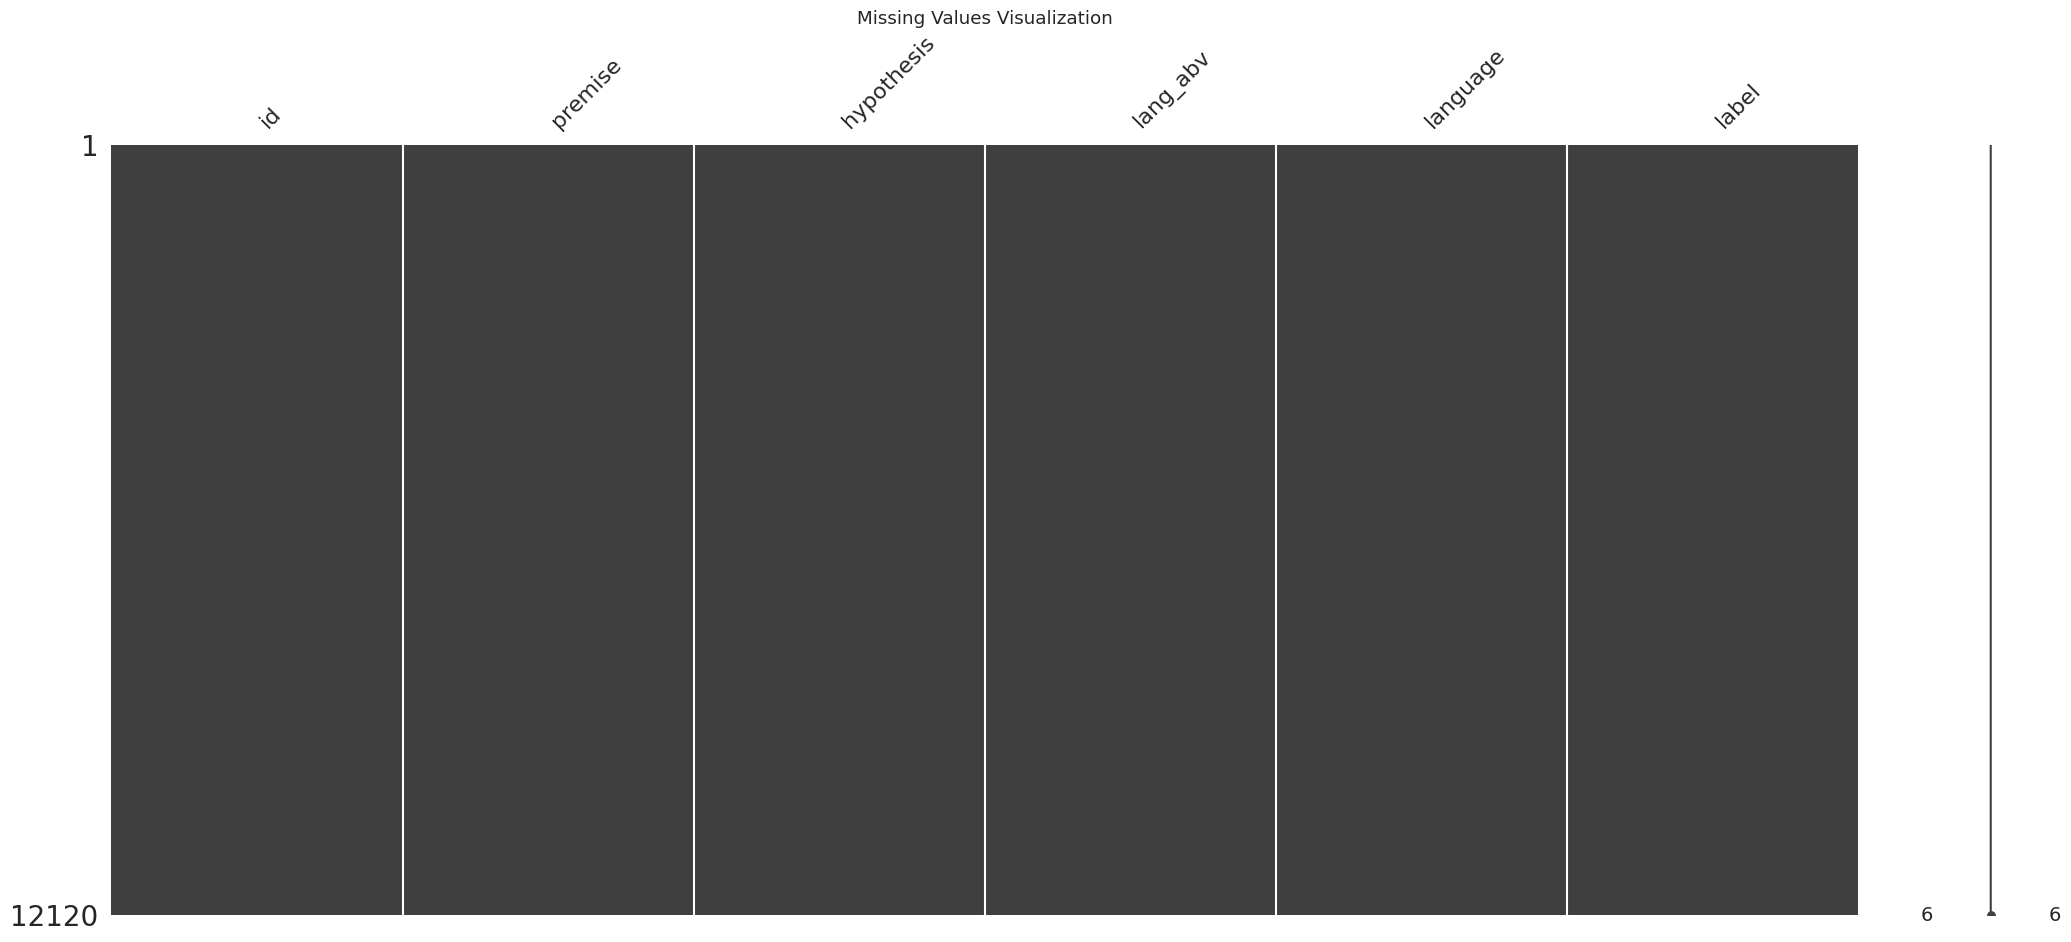

In [8]:
plt.figure(figsize=(8,4))
msno.matrix(train_df)
plt.title("Missing Values Visualization")
plt.show()

As mentioned the dataset is completely free of missing values, and all columns appear entirely black in the visualization, where black indicates that the data is fully populated

- duplicate check

In [9]:
dup_full = train_df.duplicated().sum()
dup_pair = train_df.duplicated(subset=["premise", "hypothesis"]).sum()
dup_id   = train_df["id"].duplicated().sum()
print("\n  Full-row duplicates:", dup_full)
print("\n  Premise hypothesis pair dups:",dup_pair)
print("\n  Duplicate IDs:",dup_id)



  Full-row duplicates: 0

  Premise hypothesis pair dups: 0

  Duplicate IDs: 0


Additionally, no duplicate records were found in the dataset.

In [10]:
#maping
label_map = {0: "Entailment", 1: "Neutral", 2: "Contradiction"}
train_df["label_name"] = train_df["label"].map(label_map)

# To simplify the classification of languages, they write whether the language is written in the Latin alphabet or not.
latin = {'English','French','German','Turkish','Bulgarian',
               'Swahili','Spanish','Vietnamese'}
train_df['script']     = train_df['language'].apply(
    lambda l: 'Latin' if l in latin else 'Non-Latin')
test_df['script']      = test_df['language'].apply(
    lambda l: 'Latin' if l in latin else 'Non-Latin')


- Label Distribution train

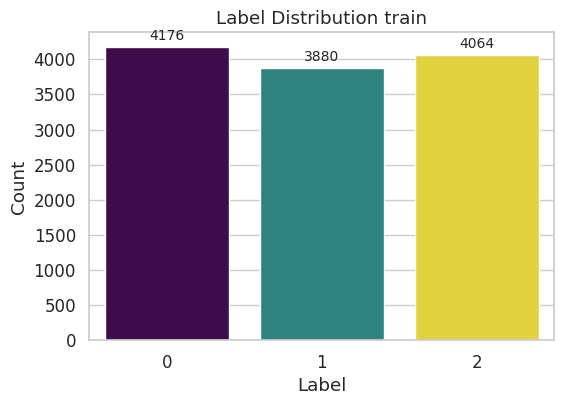

In [12]:
plt.figure(figsize=(6,4))
plt1= sns.countplot(x=train_df["label"], hue=train_df["label"], palette="viridis", legend=False)
for container in plt1.containers:
    plt1.bar_label(container, padding=3, fontsize=10)
plt.title("Label Distribution train")
plt.xlabel("Label")

plt.ylabel("Count")
plt.show()



This bar chart shows the frequency distribution of the three main classes (0, 1, 2) in the training dataset. Class 0 with more than 4000 samples, has the highest share while class 1 with 3880 samples, has the lowest share. Therefore the dataset is considered balanced. This balance helps ensure that the model does not become biased toward a specific class during learning

- Language Distribution Train

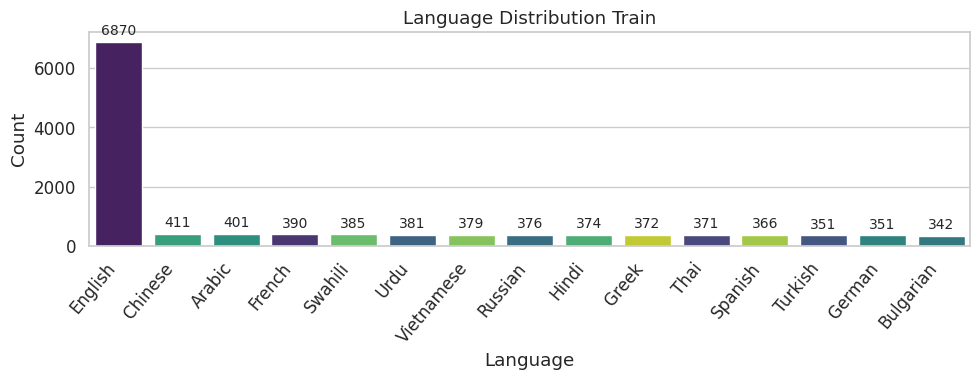

In [13]:
plt.figure(figsize=(10, 4))

plt2= sns.countplot(data=train_df, x="language", hue="language", palette="viridis", legend=False,order=train_df["language"].value_counts().index)
plt.title("Language Distribution Train")
plt.xlabel("Language")
plt.ylabel("Count")
for container in plt2.containers:
    plt2.bar_label(container, padding=3, fontsize=10)
plt.xticks(rotation=50, ha='right')
plt.tight_layout()
plt.show()

This chart shows that English has the largest share in the dataset with 6870 samples. In contrast other languages such as Chinese, Arabic, and French have very similar frequencies each ranging approximately between 340 and 410 samples.This indicates a clear imbalance between English and the other languages suggesting that the model may achieve higher performance on English. However the distribution among the remaining languages remains relatively uniform.

- labels latin scripts and labels non-latin scripts

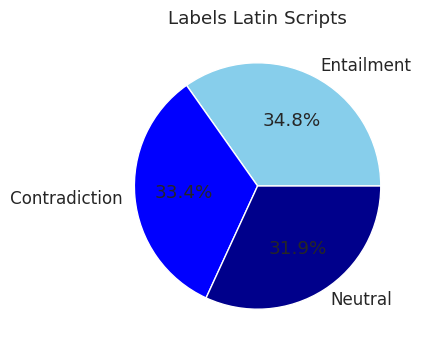

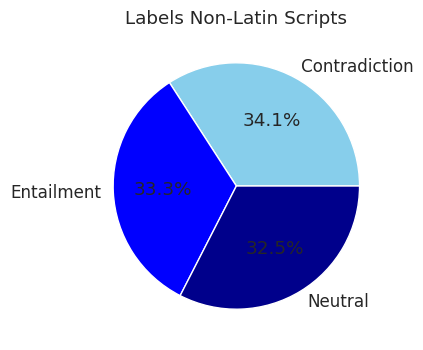

In [14]:
d_latin = train_df[train_df['script'] == 'Latin']['label_name'].value_counts()
plt.figure(figsize=(6, 4))
plt.pie(d_latin, labels=d_latin.index, autopct='%1.1f%%',colors=['skyblue','blue','darkblue'])
plt.title("Labels Latin Scripts")
plt.show()


d_non_latin = train_df[train_df['script'] == 'Non-Latin']['label_name'].value_counts()
plt.figure(figsize=(6, 4))
plt.pie(d_non_latin, labels=d_non_latin.index, autopct='%1.1f%%', colors=['skyblue','blue','darkblue'])
plt.title("Labels Non-Latin Scripts")
plt.show()


These two pie charts compare the class distribution between Latin and non‑Latin categories. In the Latin scripts Entailment has the highest share with 34.8% while in the non‑Latin scripts, Contradiction has the largest share with 34.1%. Overall the distribution in both groups is relatively uniform, indicating that being Latin or non‑Latin does not have a significant effect on the logical distribution of labels

- Label per Language

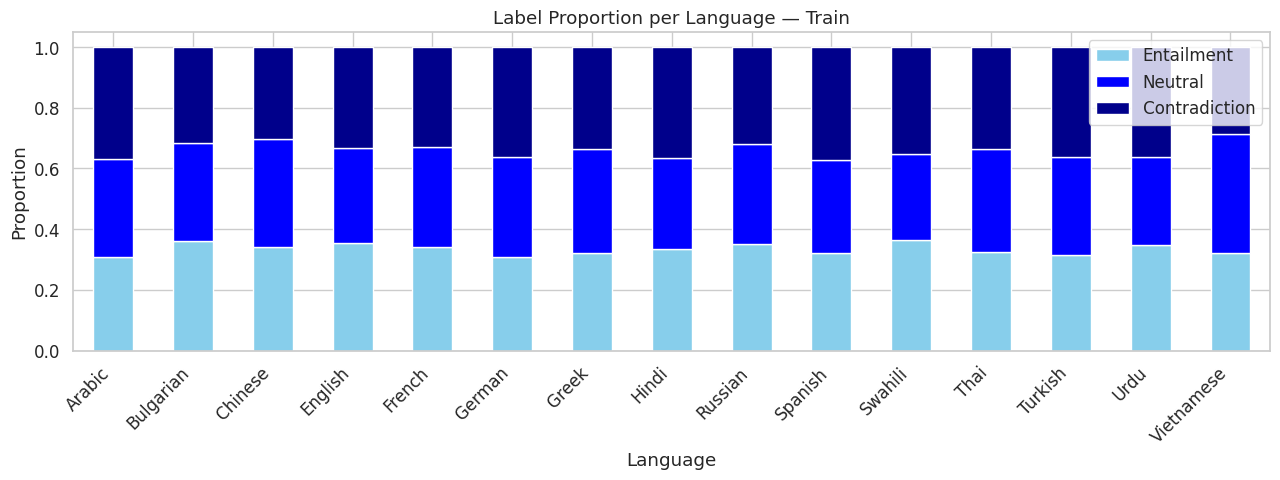

In [15]:
ll     = train_df.groupby(["language", "label"]).size().unstack(fill_value=0)
ll.columns = [label_map[c] for c in ll.columns]
ll_pct = ll.div(ll.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(13, 5))
ll_pct.plot(kind="bar", stacked=True, ax=ax,color=['skyblue','blue','darkblue'])
ax.set_title("Label Proportion per Language — Train")
ax.set_ylabel("Proportion")
ax.set_xlabel("Language")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

This chart examines the class distribution across each of the 15 languages in the dataset. In all languages (from Arabic to Vietnamese), the proportions of the three classes are almost equal and there is no language in which a specific class dominates. This suggests that the samples were generated or translated without bias during the data creation process. As a result, the model has an equal opportunity to predict each of the three classes across all languages

- Text Length Distribution

       premise_len  hypothesis_len
count      12120.0         12120.0
mean          18.0             9.2
std           12.9             4.7
min            1.0             1.0
25%            9.0             6.0
50%           16.0             9.0
75%           25.0            12.0
max          196.0            46.0


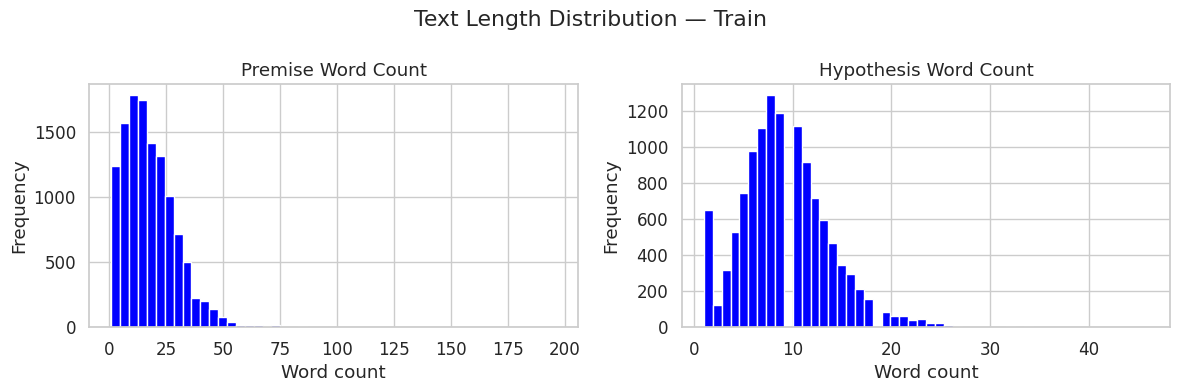

In [16]:
train_df["premise_len"]    = train_df["premise"].astype(str).apply(lambda x: len(x.split()))
train_df["hypothesis_len"] = train_df["hypothesis"].astype(str).apply(lambda x: len(x.split()))

print(train_df[["premise_len", "hypothesis_len"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in zip(axes,
                           ["premise_len", "hypothesis_len"],
                           ["Premise Word Count", "Hypothesis Word Count"]):
    ax.hist(train_df[col], bins=50, color="blue", edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel("Word count")
    ax.set_ylabel("Frequency")
plt.suptitle("Text Length Distribution — Train")
plt.tight_layout()
plt.show()

The analysis of sentence lengths shows that the Premise with an average of 18 words is significantly longer than the Hypothesis, which has an average of 9 words. Both distributions are strongly right-skewed and contain outliers, with sentence lengths reaching up to 196 words in the Premise section.

# TEXT PREPROCESSING

In [17]:
NEGATION_TOKENS = {
    'not', "n't", 'no', 'never', 'neither', 'nor',  # English
    'ne', 'pas', 'jamais', 'rien',                   # French
    'nicht', 'kein', 'keine', 'nein',                # German
    'no', 'nunca', 'jamás', 'tampoco',               # Spanish
    'نه', 'نمی', 'نیست', 'هرگز',                    # Persian/Urdu
    'değil', 'hiç',                                  # Turkish
    'не', 'нет', 'никогда',                          # Russian/Bulgarian
    'hapana', 'si',                                  # Swahili
}

In [18]:
def preprocess(text: str, lang: str) -> str:
    if not isinstance(text, str):
        return ''
    text = unicodedata.normalize('NFC', text)
    text = re.sub(r'[\u200b\u200c\u200d\ufeff]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    if lang in latin:
        text = text.lower()
    return text

for df in [train_df, test_df]:
    df['p_clean'] = df.apply(
        lambda r: preprocess(r['premise'],    r['language']), axis=1)
    df['h_clean'] = df.apply(
        lambda r: preprocess(r['hypothesis'], r['language']), axis=1)


First, lowercasing was applied only to Latin-script languages such as English, French, and German, since differences between uppercase and lowercase letters in these languages usually do not carry significant semantic meaning. In contrast, languages such as Arabic, Thai, and Chinese were excluded from this step because their writing systems can be sensitive to character-level changes. Additionally, negation tokens such as not, never, ne…pas, and nami were intentionally preserved because these words play a crucial role in distinguishing between the Entailment and Contradiction classes, and removing them could lead to the loss of important semantic information. Furthermore, Unicode normalization (NFC) was applied globally to the dataset in order to resolve potential encoding inconsistencies across multilingual texts. Finally, stop words were not removed, since eliminating them could disrupt important semantic relationships and sentence structures needed for accurate interpretation

In [ ]:
def word_overlap(p: str, h: str) -> float:
    pw, hw = set(p.split()), set(h.split())
    return len(pw & hw) / len(hw) if hw else 0.0

def jaccard(p: str, h: str) -> float:
    pw, hw = set(p.split()), set(h.split())
    u = pw | hw
    return len(pw & hw) / len(u) if u else 0.0

def len_diff(p: str, h: str) -> float:
    pl, hl = len(p.split()), len(h.split())
    t = pl + hl
    return abs(pl - hl) / t if t else 0.0

def neg_count(text: str) -> int:
    return len(set(text.lower().split()) & NEGATION_TOKENS)

for df in [train_df, test_df]:
    df['word_overlap'] = df.apply(
        lambda r: word_overlap(r['p_clean'], r['h_clean']), axis=1)
    df['jaccard']      = df.apply(
        lambda r: jaccard(r['p_clean'],      r['h_clean']), axis=1)
    df['len_diff']     = df.apply(
        lambda r: len_diff(r['p_clean'],     r['h_clean']), axis=1)
    df['neg_p']        = df['p_clean'].apply(neg_count)
    df['neg_h']        = df['h_clean'].apply(neg_count)
    df['neg_diff']     = df['neg_h'] - df['neg_p']

tr_cos, te_cos = {}, {}
for lang in train_df['language'].unique():
    tr_idx = train_df[train_df['language'] == lang].index
    te_idx = test_df[test_df['language']   == lang].index

    vect = TfidfVectorizer(
        analyzer='word',
        token_pattern=r'(?u)\S+',   
        min_df=1,
        sublinear_tf=True,)
    vect.fit(train_df.loc[tr_idx, 'p_clean'].tolist() +
             train_df.loc[tr_idx, 'h_clean'].tolist())

    pv = vect.transform(train_df.loc[tr_idx, 'p_clean'])
    hv = vect.transform(train_df.loc[tr_idx, 'h_clean'])
    for i, s in zip(tr_idx, cosine_similarity(pv, hv).diagonal()):
        tr_cos[i] = s

    if len(te_idx):
        pv2 = vect.transform(test_df.loc[te_idx, 'p_clean'])
        hv2 = vect.transform(test_df.loc[te_idx, 'h_clean'])
        for i, s in zip(te_idx, cosine_similarity(pv2, hv2).diagonal()):
            te_cos[i] = s


In [20]:
train_df['tfidf_cos'] = pd.Series(tr_cos).reindex(train_df.index).fillna(0)
test_df['tfidf_cos']  = pd.Series(te_cos).reindex(test_df.index).fillna(0)

FEATS = ['word_overlap', 'jaccard', 'tfidf_cos','len_diff', 'neg_p', 'neg_h', 'neg_diff']


- Key Features by Label

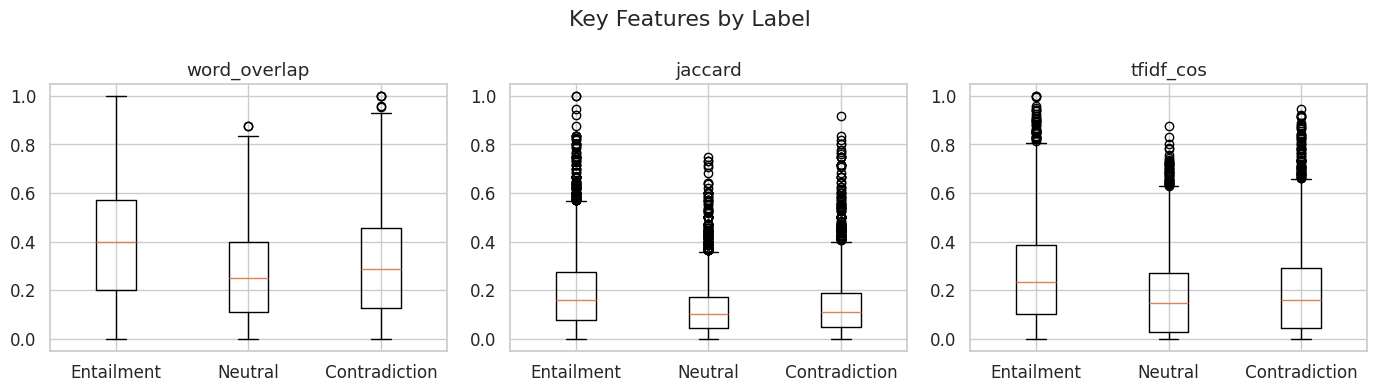

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14,4))

for i, feat in enumerate(['word_overlap', 'jaccard', 'tfidf_cos']):
    axes[i].boxplot(
        [train_df[train_df['label']==l][feat] for l in [0,1,2]],
        tick_labels=['Entailment', 'Neutral', 'Contradiction']
    )
    axes[i].set_title(feat)

plt.suptitle('Key Features by Label')
plt.tight_layout()
plt.show()

These boxplots show that the Entailment class has higher values across all three metrics—word overlap, Jaccard coefficient, and TF‑IDF cosine similarity—compared to the Neutral and Contradiction classes.This is because semantically aligned or inferential sentence pairs tend to share more common vocabulary, resulting in higher similarity scores across lexical and vector‑based measures. In contrast the Neutral and Contradiction classes display similar dispersion patterns in the plots. This suggests that distinguishing between these two classes using only these simple surface‑level features is more challenging.

In [22]:
print('Feature stats by label:')
print(train_df[FEATS + ['label']].groupby('label').mean().round(3))


Feature stats by label:
       word_overlap  jaccard  tfidf_cos  len_diff  neg_p  neg_h  neg_diff
label                                                                    
0             0.391    0.186      0.257     0.301  0.103  0.077    -0.027
1             0.261    0.122      0.174     0.297  0.099  0.071    -0.028
2             0.302    0.135      0.191     0.313  0.095  0.205     0.110


- Correlation Heatmap

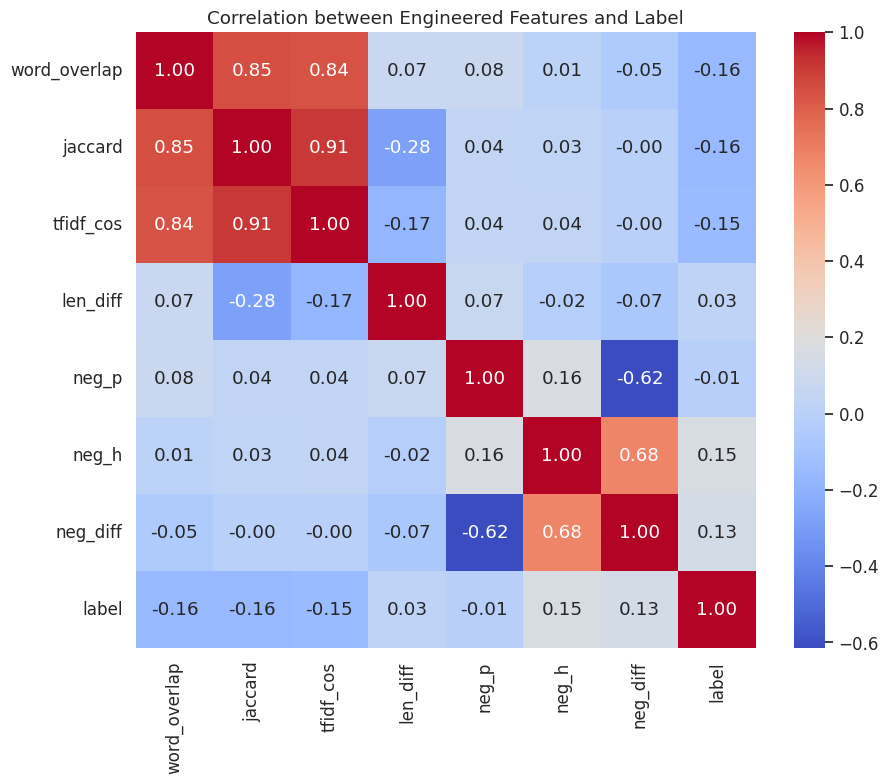

In [23]:

plt.figure(figsize=(10, 8))
corr_matrix = train_df[FEATS + ['label']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation between Engineered Features and Label")
plt.show()


This figure shows a correlation matrix indicating that the features word_overlap, jaccard, and tfidf_cos have a very high correlation with each other (above 0.84). This means they capture very similar information, so the model should avoid relying too heavily on all three simultaneously.Additionally, the correlation between these features and the label column is very low (close to zero). This suggests that the relationships in this dataset are not linear

In [24]:
#Feature Importance Insight
analysis = train_df.groupby('label_name')[['word_overlap', 'tfidf_cos', 'jaccard']].mean()
print(analysis)


               word_overlap  tfidf_cos   jaccard
label_name                                      
Contradiction      0.301964   0.190993  0.134812
Entailment         0.390980   0.257472  0.186116
Neutral            0.260671   0.173784  0.121611


During the feature engineering stage three lexical overlap features were computed for each Premise–Hypothesis pair. The first feature, Word Overlap Ratio, measures the percentage of words in the hypothesis that also appear in the premise. A high overlap can often indicate the Entailment or Neutral classes. The second feature, Jaccard Similarity calculates the ratio of the intersection to the union of the word sets from the two sentences providing a symmetric measure of lexical overlap. The third feature TF‑IDF Cosine Similarity measures the semantic similarity between the two sentences using TF‑IDF vector representations where words are weighted based on their importance.However Contradiction pairs can also exhibit a high level of surface-level lexical overlap similar to Entailment pairs. Therefore relying solely on lexical features is not sufficient to effectively distinguish between these classes.

In [25]:
train_df.to_csv('data/train_processed.csv', index=False)

test_df.to_csv('data/test_processed.csv',   index=False)

---
# Phase II: Transformer-Based Predictive Modeling


In the training dataset there was a slight class imbalance among the three classes; however it can effectively be considered balanced. Therefore the standard CrossEntropyLoss function was used without applying class weights, since this minor imbalance is unlikely to introduce significant bias into the model. Moreover the primary evaluation metric ,Macro F1, inherently assigns equal weight to all classes regardless of their support. Additionally, applying class weighting in a near-balanced setting may introduce unnecessary variance into the training process. Finally the default 0.5 probability threshold was used for final class assignment. Given the balanced distribution and the objective of maximizing Macro F1, threshold adjustment was not necessary

In [26]:
#seed=42
import random
def set_seed(s=42):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    os.environ['PYTHONHASHSEED'] = str(s)

set_seed()

In [27]:
train = pd.read_csv('data/train_processed.csv')
test  = pd.read_csv('data/test_processed.csv')
#sample_submission

label = ['Entailment', 'Neutral', 'Contradiction']

premises_all   = train['p_clean'].tolist()
hypotheses_all = train['h_clean'].tolist()
labels_all     = train['label'].tolist()

print(f'train: {len(train)}   test: {len(test)}')
print(f'Label counts: {np.bincount(labels_all)}')

train: 12120   test: 5195
Label counts: [4176 3880 4064]


In [28]:

MODEL_NAME   = 'xlm-roberta-base'
MAX_LEN      = 128
N_FOLDS      = 3
N_LABELS     = 3
WARMUP_RATIO = 0.1

PARAM_GRID = [
    {'lr': 2e-5, 'batch_size': 16, 'epochs': 3},
    {'lr': 3e-5, 'batch_size': 16, 'epochs': 3},
    {'lr': 2e-5, 'batch_size': 16, 'epochs': 4},]


In [29]:
class NLIDataset(Dataset):

    def __init__(self, premises, hypotheses, tokenizer, max_len, labels=None):
        self.premises   = premises
        self.hypotheses = hypotheses
        self.tokenizer  = tokenizer
        self.max_len    = max_len
        self.labels     = labels

    def __len__(self): return len(self.premises)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.premises[idx], self.hypotheses[idx],
            max_length=self.max_len, padding='max_length',
            truncation=True, return_tensors='pt',
        )
        item = {
            'input_ids':      enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
        }
        if self.labels is not None:
            item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


In [30]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


In [31]:

def train_epoch(model, loader, optimizer, scheduler, criterion):
    model.train()
    total = 0
    for batch in loader:
        optimizer.zero_grad()
        ids  = batch['input_ids'].to(DEVICE)
        mask = batch['attention_mask'].to(DEVICE)
        lbls = batch['labels'].to(DEVICE)
        loss = criterion(model(input_ids=ids, attention_mask=mask).logits, lbls)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # prevent exploding gradients
        optimizer.step(); scheduler.step()
        total += loss.item()
    return total / len(loader)

def softmax(x):
    e = np.exp(x - x.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def evaluate(model, loader):
    model.eval()
    logits_all, labels_all = [], []
    with torch.no_grad():
        for batch in loader:
            ids  = batch['input_ids'].to(DEVICE)
            mask = batch['attention_mask'].to(DEVICE)
            logits_all.append(model(input_ids=ids, attention_mask=mask).logits.cpu().numpy())
            if 'labels' in batch:
                labels_all.append(batch['labels'].numpy())
    logits = np.concatenate(logits_all)
    probs  = softmax(logits)
    preds  = np.argmax(probs, axis=1)
    labels = np.concatenate(labels_all) if labels_all else None
    return preds, probs, labels


In [32]:

tokenizer    = AutoTokenizer.from_pretrained(MODEL_NAME)
criterion    = nn.CrossEntropyLoss()   # balanced data — no weights
skf          = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
grid_results = []

for params in PARAM_GRID:
    lr, bs, epochs = params['lr'], params['batch_size'], params['epochs']
    fold_f1s = []

    for fold, (tr_idx, val_idx) in enumerate(skf.split(premises_all, labels_all)):
        print(f'  {params}  Fold {fold+1}/{N_FOLDS}')
        tr_ds  = NLIDataset([premises_all[i]   for i in tr_idx],
                            [hypotheses_all[i] for i in tr_idx],
                            tokenizer, MAX_LEN,
                            [labels_all[i]     for i in tr_idx])
        val_ds = NLIDataset([premises_all[i]   for i in val_idx],
                            [hypotheses_all[i] for i in val_idx],
                            tokenizer, MAX_LEN,
                            [labels_all[i]     for i in val_idx])
        tr_loader  = DataLoader(tr_ds,  batch_size=bs, shuffle=True,  num_workers=2)
        val_loader = DataLoader(val_ds, batch_size=bs, shuffle=False, num_workers=2)

        model = AutoModelForSequenceClassification.from_pretrained(
            MODEL_NAME, num_labels=N_LABELS).to(DEVICE)
        optimizer = AdamW(model.parameters(), lr=lr, weight_decay=0.01)
        total_steps = len(tr_loader) * epochs
        scheduler   = get_linear_schedule_with_warmup(
            optimizer, int(total_steps * WARMUP_RATIO), total_steps)

        best_f1 = 0
        for ep in range(epochs):
            loss = train_epoch(model, tr_loader, optimizer, scheduler, criterion)
            preds, _, true = evaluate(model, val_loader)
            f1 = f1_score(true, preds, average='macro')
            print(f'    Epoch {ep+1}: loss={loss:.4f}  val_f1={f1:.4f}')
            best_f1 = max(best_f1, f1)
        fold_f1s.append(best_f1)

    mean_f1 = np.mean(fold_f1s)
    std_f1  = np.std(fold_f1s)
    print(f'  >> Mean F1={mean_f1:.4f} ± {std_f1:.4f}\n')
    grid_results.append({**params, 'mean_f1': mean_f1, 'std_f1': std_f1})

res_df      = pd.DataFrame(grid_results).sort_values('mean_f1', ascending=False)
best_params = res_df.iloc[0].to_dict()
print('Best params:')
print(res_df.to_string(index=False))


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

...

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    Epoch 1: loss=1.1019  val_f1=0.1974
    Epoch 2: loss=1.1015  val_f1=0.1708
    Epoch 3: loss=1.0997  val_f1=0.1708
    Epoch 4: loss=1.0992  val_f1=0.2432
  {'lr': 2e-05, 'batch_size': 16, 'epochs': 4}  Fold 3/3


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    Epoch 1: loss=1.0891  val_f1=0.5567
    Epoch 2: loss=0.9082  val_f1=0.6687
    Epoch 3: loss=0.7107  val_f1=0.6823
    Epoch 4: loss=0.5595  val_f1=0.7063
  >> Mean F1=0.5479 ± 0.2155

Best params:
     lr  batch_size  epochs  mean_f1   std_f1
0.00002          16       3 0.695933 0.007230
0.00003          16       3 0.580332 0.160653
0.00002          16       4 0.547916 0.215510


In this experiment, the xlm-roberta-base model was fine-tuned using Stratified 3-Fold Cross-Validation. The best performance was achieved with the configuration lr = 2e-5, batch_size = 16, and 3 epochs, obtaining an F1-score of 0.6959, which showed the most accurate and stable result with the lowest standard deviation. However, increasing the learning rate to 3e-5 or the number of epochs to 4 led to a decline in performance and higher instability, reflected by large fluctuations in the F1-score. The high standard deviation observed in these unsuccessful configurations indicates that the model becomes overly sensitive to the training data in some folds and may suffer from overfitting or improper convergence

- Final training: lr=2e-05  bs=16  epochs=3


In [33]:
BEST_LR, BEST_BS, BEST_EP = best_params['lr'], int(best_params['batch_size']), int(best_params['epochs'])
print(f'\nFinal training: lr={BEST_LR}  bs={BEST_BS}  epochs={BEST_EP}')

full_ds     = NLIDataset(premises_all, hypotheses_all, tokenizer, MAX_LEN, labels_all)
full_loader = DataLoader(full_ds, batch_size=BEST_BS, shuffle=True, num_workers=2)
test_ds     = NLIDataset(test['p_clean'].tolist(), test['h_clean'].tolist(), tokenizer, MAX_LEN)
test_loader = DataLoader(test_ds, batch_size=BEST_BS, shuffle=False, num_workers=2)

final_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=N_LABELS).to(DEVICE)
optimizer   = AdamW(final_model.parameters(), lr=BEST_LR, weight_decay=0.01)
total_steps = len(full_loader) * BEST_EP
scheduler   = get_linear_schedule_with_warmup(
    optimizer, int(total_steps * WARMUP_RATIO), total_steps)

for ep in range(BEST_EP):
    loss = train_epoch(final_model, full_loader, optimizer, scheduler, criterion)
    print(f'  Epoch {ep+1}/{BEST_EP}  loss={loss:.4f}')

final_model.save_pretrained('outputs/xlmr_nli_model')
tokenizer.save_pretrained('outputs/xlmr_nli_model')



Final training: lr=2e-05  bs=16  epochs=3


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 1/3  loss=1.0066
  Epoch 2/3  loss=0.7380
  Epoch 3/3  loss=0.5568


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved: xlmr_nli_model/


The final model was trained using the configuration learning rate = 2e-5 batch size = 16 and 3 epochs. During training, the loss value decreased steadily from 1.0066 in the first epoch to 0.5568 in the third epoch indicating stable learning and proper convergence of the model

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Classification Report:
               precision    recall  f1-score   support

   Entailment       0.71      0.75      0.73      1392
      Neutral       0.65      0.65      0.65      1294
Contradiction       0.72      0.69      0.71      1354

     accuracy                           0.70      4040
    macro avg       0.70      0.70      0.70      4040
 weighted avg       0.70      0.70      0.70      4040

Macro ROC-AUC: 0.8594


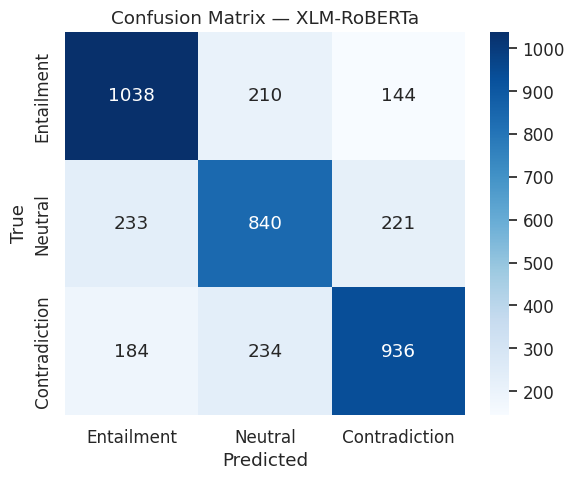

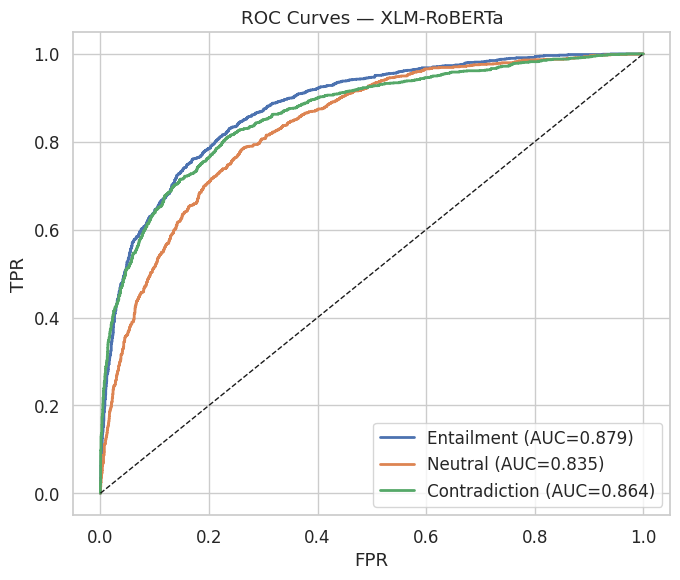

Distribution: {np.int64(0): np.int64(1773), np.int64(1): np.int64(1852), np.int64(2): np.int64(1570)}


In [34]:

last_tr, last_val = list(skf.split(premises_all, labels_all))[-1]
eval_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=N_LABELS).to(DEVICE)
e_ds  = NLIDataset([premises_all[i]   for i in last_tr],
                   [hypotheses_all[i] for i in last_tr],
                   tokenizer, MAX_LEN,
                   [labels_all[i]     for i in last_tr])
ve_ds = NLIDataset([premises_all[i]   for i in last_val],
                   [hypotheses_all[i] for i in last_val],
                   tokenizer, MAX_LEN,
                   [labels_all[i]     for i in last_val])
e_loader  = DataLoader(e_ds,  batch_size=BEST_BS, shuffle=True)
ve_loader = DataLoader(ve_ds, batch_size=BEST_BS, shuffle=False)
opt2 = AdamW(eval_model.parameters(), lr=BEST_LR, weight_decay=0.01)
tot2 = len(e_loader) * BEST_EP
sch2 = get_linear_schedule_with_warmup(opt2, int(tot2*WARMUP_RATIO), tot2)
for _ in range(BEST_EP):
    train_epoch(eval_model, e_loader, opt2, sch2, criterion)

val_preds, val_probs, val_true = evaluate(eval_model, ve_loader)
print('\nClassification Report:')
print(classification_report(val_true, val_preds, target_names=label))
roc_auc = roc_auc_score(pd.get_dummies(val_true).values, val_probs,
                        multi_class='ovr', average='macro')
print(f'Macro ROC-AUC: {roc_auc:.4f}')

# Confusion matrix
cm = confusion_matrix(val_true, val_preds)
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label, yticklabels=label)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — XLM-RoBERTa')
plt.tight_layout();plt.show()

# ROC curves
y_bin = pd.get_dummies(val_true).values
fig, ax = plt.subplots(figsize=(7,6))
for i,(lbl,col) in enumerate(zip(label,['#4C72B0','#DD8452','#55A868'])):
    fpr,tpr,_ = roc_curve(y_bin[:,i], val_probs[:,i])
    ax.plot(fpr,tpr,color=col,lw=2,label=f'{lbl} (AUC={auc(fpr,tpr):.3f})')
ax.plot([0,1],[0,1],'k--',lw=1)
ax.set_title('ROC Curves — XLM-RoBERTa')
ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.legend(loc='lower right'); plt.tight_layout()
plt.show()

test_preds, _, _ = evaluate(final_model, test_loader)
sample_submission['prediction'] = test_preds
print(f'Distribution: {dict(zip(*np.unique(test_preds, return_counts=True)))}')
sample_submission.to_csv('outputs/submission.csv', index=False)   # Kaggle submission file


The final classification report demonstrates that for the Entailment class, the model achieved a precision of 0.71, a recall of 0.75, and an F1-score of 0.73. Consequently, the model exhibits strong capabilities in identifying entailment relationships, outperforming its ability to recognize the other classes. For the Neutral class, the precision, recall, and F1-score are all 0.65. Regarding the Contradiction class, the reported precision, recall and F1-score are 0.72, 0.69, and 0.71, respectively, confirming effective performance in detecting contradictions.The model achieved an overall accuracy of approximately 0.70 which is a satisfactory outcome for a three-class natural language processing task. Furthermore, both the macro-averaged and weighted-averaged metrics are 0.70, validating the balanced nature of the model is performance. The proximity of these values suggests that there is no significant disparity between the performance across classes. In summary while the model has reached a consistent and reliable level of performance the Neutral class still presents potential for further improvement


A Macro ROC-AUC value of 0.8594 indicates that the model performs exceptionally well in distinguishing between the three primary classes and can effectively differentiate between positive and negative instances in most cases. Consequently, this value demonstrates that the model is not biased towards any single class but rather exhibits strong overall generalization.

The confusion matrix also reveals that the model achieved the highest number of correct predictions for the Entailment class correctly identifying 1038 out of 1392 actual entailment instances. For the Neutral class, 840 instances were predicted correctly, though it incurred more errors compared to the other two classes. In the Contradiction class 936 correct predictions were recorded, indicating satisfactory performance. The majority of classification errors occurred at the boundary between the Neutral class and the other two classes. This is primarily because the Neutral class is semantically more ambiguous and less definitive meaning the model still faces challenges in distinguishing between closely related semantic concepts

The ROC curves demonstrate that the XLM-RoBERTa model possesses robust discrimination capability across all three classes. The Entailment class achieved the highest AUC of 0.879 indicating that the model is highly effective in distinguishing this relationship from the others. For the Neutral class an AUC of 0.835 was obtained; although this is lower than the other two classes, it remains within an acceptable range, given the inherent ambiguity of the Neutral category. Furthermore an AUC of 0.864 was reported for the Contradiction class, highlighting the model’s strong performance in identification. The significant distance of these curves from the random diagonal line demonstrates that the model consistently outperforms random chance across all classes. Finally the overall shape of the curves suggests that the model maintains appropriate sensitivity across various false positive rates

# Phase III: Traditional ML Models and Comparison


In [36]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


In [37]:
MODELS = {
    'Logistic Regression': {
        'pipe': Pipeline([
            ('sc',  StandardScaler()),
            ('clf', LogisticRegression(
                max_iter=1000, solver='lbfgs', random_state=42)),
        ]),
        'grid': {'clf__C': [0.01, 0.1, 1, 10, 100]},
    },
    'Random Forest': {
        'pipe': Pipeline([
            ('clf', RandomForestClassifier(random_state=42, n_jobs=-1)),
        ]),
        'grid': {
            'clf__n_estimators':      [100, 200, 300],
            'clf__max_depth':         [None, 10, 20],
            'clf__min_samples_split': [2, 5, 10],
        },
    },
    'SVM': {
        'pipe': Pipeline([
            ('sc',  StandardScaler()),
            ('clf', CalibratedClassifierCV(
                LinearSVC(max_iter=5000, random_state=42), cv=3)),
        ]),
        'grid': {'clf__estimator__C': [0.1, 1, 10]},
    },

    'XGBoost': {
        'pipe': Pipeline([
            ('sc',  StandardScaler()),
            ('clf', XGBClassifier(
                eval_metric='mlogloss',
                use_label_encoder=False,
                random_state=42,
                n_jobs=-1,
            )),
        ]),
        'grid': {
            'clf__n_estimators':  [100, 200],
            'clf__max_depth':     [3, 5, 7],
            'clf__learning_rate': [0.05, 0.1],
            'clf__subsample':     [0.8, 1.0],
        },
    },
}

In [38]:
X_train = train[FEATS].values
y_train = train['label'].values
X_test  = test[FEATS].values
print(f'Train: {X_train.shape}  |  Test: {X_test.shape}')
print(f'Label counts: {np.bincount(y_train)}  (balanced — no weighting needed)\n')


Train: (12120, 7)  |  Test: (5195, 7)
Label counts: [4176 3880 4064]  (balanced — no weighting needed)



In [ ]:

results = {}

for name, cfg in MODELS.items():
    print(f' {name}')

    search = RandomizedSearchCV(
        cfg['pipe'], cfg['grid'],
        n_iter=8, scoring='f1_macro',
        cv=CV, refit=True, random_state=42, n_jobs=-1,
    )
    search.fit(X_train, y_train)
    best = search.best_estimator_
    print(f'  Best params : {search.best_params_}')

    # Out-of-fold predictions unbiased metrics
    oof_preds = np.zeros(len(y_train), dtype=int)
    oof_probs = np.zeros((len(y_train), 3))
    for tr_idx, val_idx in CV.split(X_train, y_train):
        best.fit(X_train[tr_idx], y_train[tr_idx])
        oof_preds[val_idx] = best.predict(X_train[val_idx])
        oof_probs[val_idx] = best.predict_proba(X_train[val_idx])

    mf1  = f1_score(y_train,      oof_preds, average='macro')
    mpr  = precision_score(y_train, oof_preds, average='macro')
    mre  = recall_score(y_train,   oof_preds, average='macro')
    rauc = roc_auc_score(pd.get_dummies(y_train).values, oof_probs,
                         multi_class='ovr', average='macro')

    print(f'  Macro F1={mf1:.4f}  Precision={mpr:.4f}  '
          f'Recall={mre:.4f}  AUC={rauc:.4f}')
    print(classification_report(y_train, oof_preds, target_names=label))

    best.fit(X_train, y_train)   # refit on full train for final predictions
    results[name] = {
        'model': best, 'oof_preds': oof_preds, 'oof_probs': oof_probs,
        'f1': mf1, 'precision': mpr, 'recall': mre, 'auc': rauc,
    }


 Logistic Regression


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 5 is smaller than n_iter=8. Running 5 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


  Best params : {'clf__C': 10}
  Macro F1=0.4319  Precision=0.4604  Recall=0.4459  AUC=0.6212
               precision    recall  f1-score   support

   Entailment       0.45      0.57      0.51      4176
      Neutral       0.41      0.52      0.46      3880
Contradiction       0.52      0.24      0.33      4064

     accuracy                           0.45     12120
    macro avg       0.46      0.45      0.43     12120
 weighted avg       0.46      0.45      0.43     12120

 Random Forest
  Best params : {'clf__n_estimators': 200, 'clf__min_samples_split': 10, 'clf__max_depth': 10}
  Macro F1=0.4531  Precision=0.4796  Recall=0.4658  AUC=0.6413
               precision    recall  f1-score   support

   Entailment       0.50      0.49      0.50      4176
      Neutral       0.41      0.63      0.50      3880
Contradiction       0.52      0.28      0.36      4064

     accuracy                           0.46     12120
    macro avg       0.48      0.47      0.45     12120
 weighted avg

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 3 is smaller than n_iter=8. Running 3 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


  Best params : {'clf__estimator__C': 10}
  Macro F1=0.4280  Precision=0.4674  Recall=0.4453  AUC=0.6205
               precision    recall  f1-score   support

   Entailment       0.45      0.58      0.51      4176
      Neutral       0.41      0.53      0.46      3880
Contradiction       0.54      0.22      0.31      4064

     accuracy                           0.45     12120
    macro avg       0.47      0.45      0.43     12120
 weighted avg       0.47      0.45      0.43     12120

 XGBoost


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:52:49] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


  Best params : {'clf__subsample': 0.8, 'clf__n_estimators': 100, 'clf__max_depth': 5, 'clf__learning_rate': 0.1}


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:52:50] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:52:51] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:52:52] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:52:53] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:

  Macro F1=0.4513  Precision=0.4627  Recall=0.4585  AUC=0.6386
               precision    recall  f1-score   support

   Entailment       0.50      0.49      0.50      4176
      Neutral       0.42      0.57      0.48      3880
Contradiction       0.47      0.31      0.38      4064

     accuracy                           0.46     12120
    macro avg       0.46      0.46      0.45     12120
 weighted avg       0.46      0.46      0.45     12120



/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:52:54] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


-Logistic Regression

The Logistic Regression model was trained using hyperparameter tuning, where the best configuration was obtained with C = 10. The model achieved a Macro F1-score of 0.4319, Precision of 0.4604, Recall of 0.4459, and AUC of 0.6212, indicating a moderate level of classification performance.In the class-wise evaluation, the model achieved the highest F1-score of 0.51 for the Entailment class. The Neutral class obtained an F1-score of 0.46, which indicates a moderate ability of the model to identify this category. However, the Contradiction class showed the weakest performance with an F1-score of 0.33, mainly due to its low Recall value of 0.24. This suggests that many samples belonging to this class were incorrectly classified as other classes.The overall accuracy of the model was 0.45. These results indicate that although Logistic Regression can capture some linear relationships in the feature space, the dataset also contains nonlinear relationships, which limits the model’s ability to fully capture the complex patterns required for this task.

- Random Forest

The Random Forest model was trained using hyperparameter tuning, and the best configuration was obtained with 200 decision trees, a maximum depth of 10, and a minimum samples split of 10. The model achieved a Macro F1-score of 0.4531, Precision of 0.4796, Recall of 0.4658, and AUC of 0.6413, which shows a slight improvement compared to the Logistic Regression model.In the class-wise evaluation, the Entailment class achieved an F1-score of 0.50, indicating a balanced performance between precision and recall. The Neutral class also obtained an F1-score of 0.50, mainly due to its relatively high recall (0.63), suggesting that the model tends to identify many Neutral samples. However, the Contradiction class still showed weaker performance with an F1-score of 0.36, primarily due to its lower recall value.The overall accuracy of the model was reported as 0.46, indicating that the Random Forest model is able to capture some nonlinear patterns in the data slightly better than simpler models.

- SVM

The Support Vector Machine (SVM) model was trained using hyperparameter tuning, where the best configuration was obtained with C = 10. The model achieved a Macro F1-score of 0.4280, Precision of 0.4674, Recall of 0.4453 and AUC of 0.6205. In the class-wise evaluation, the Entailment class showed the best performance with an F1-score of 0.51 indicating the model’s relative ability to identify this type of relationship. The Neutral class achieved an F1-score of 0.46 which is similar to the performance of the Logistic Regression model. However, the Contradiction class showed the lowest performance with an F1-score of 0.31, mainly due to the very low recall value of 0.22. The overall accuracy of the model was reported as 0.45 indicating relatively weak performance for this task.

- XGBoost 

The XGBoost model was trained using hyperparameter tuning, and the best configuration included 100 estimators (n_estimators = 100), a maximum depth of 5 (max_depth = 5), a learning rate of 0.1 (learning_rate = 0.1), and a subsample ratio of 0.8 (subsample = 0.8). The model achieved a Macro F1-score of 0.4513, Precision of 0.4627, Recall of 0.4585, and AUC of 0.6386.In the class-wise evaluation, the Entailment class achieved an F1-score of 0.50, indicating balanced performance in classifying this relationship. The Neutral class obtained an F1-score of 0.48, partly due to its relatively higher recall (0.57). The Contradiction class achieved an F1-score of 0.38, which is slightly better than the other classical models, but it still remains considerably lower than the other two classes.The overall accuracy of the model was reported as 0.46, indicating that gradient boosting–based methods are generally more capable of learning nonlinear relationships compared to simpler models. However, despite this improvement, the overall performance of this model is still relatively weak for the task.

In [46]:

comp = pd.DataFrame([
    {'Model': n, 'Precision': v['precision'],
     'Recall': v['recall'], 'F1': v['f1'], 'AUC': v['auc']}
    for n, v in results.items()
]).sort_values('F1', ascending=False).reset_index(drop=True)

print(comp.round(4).to_string(index=False))



              Model  Precision  Recall     F1    AUC
      Random Forest     0.4796  0.4658 0.4531 0.6413
            XGBoost     0.4627  0.4585 0.4513 0.6386
Logistic Regression     0.4604  0.4459 0.4319 0.6212
                SVM     0.4674  0.4453 0.4280 0.6205


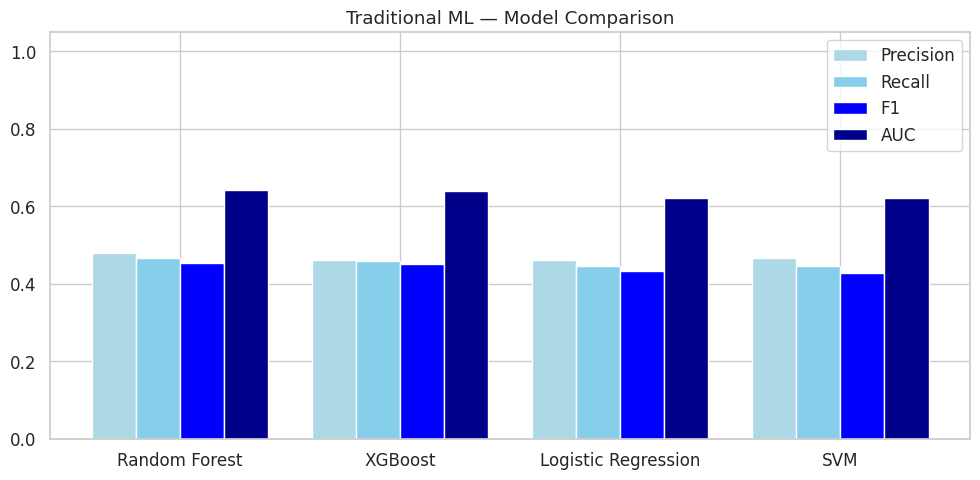

In [47]:

fig, ax = plt.subplots(figsize=(10,5))
x = np.arange(len(comp))
w = 0.2

blue_shades = ['lightblue', 'skyblue', 'blue', 'darkblue']

for i, (m, c) in enumerate(zip(
        ['Precision', 'Recall', 'F1', 'AUC'],
        blue_shades)):
    ax.bar(x + i*w, comp[m], w, label=m, color=c)

ax.set_xticks(x + w*1.5)
ax.set_xticklabels(comp['Model'])
ax.set_ylim(0, 1.05)
ax.set_title('Traditional ML — Model Comparison')
ax.legend()

plt.tight_layout()
plt.show()

This comparative chart demonstrates that among the evaluated models, Random Forest achieved the best overall performance. As illustrated in the figure this model obtained the highest values for Precision, Recall, F1-score, and AUC compared to the other models. Following closely behind XGBoost exhibits a performance highly comparable to Random Forest with only a marginal difference observed between the two models

In [48]:
best_name = comp.iloc[0]['Model']
best      = results[best_name]
print(f'\n Best Model: {best_name} ')
print(classification_report(y_train, best['oof_preds'], target_names=label))



 Best Model: Random Forest 
               precision    recall  f1-score   support

   Entailment       0.50      0.49      0.50      4176
      Neutral       0.41      0.63      0.50      3880
Contradiction       0.52      0.28      0.36      4064

     accuracy                           0.46     12120
    macro avg       0.48      0.47      0.45     12120
 weighted avg       0.48      0.46      0.45     12120



This table presents the performance of the Random Forest model on the test dataset. The model achieved an overall accuracy of 0.46, indicating that it correctly classified approximately 46% of the samples. In addition, the macro average values for Precision, Recall, and F1-score are 0.48, 0.47, and 0.45, respectively, which reflects a moderate performance across the three classes. The weighted average F1-score is 0.45, suggesting that even after considering the distribution of samples across classes, the overall performance of the model remains at a moderate level.When examining the model’s performance for each class individually, the Entailment class shows a Precision of 0.50 and a Recall of 0.49, resulting in an F1-score of 0.50. These results indicate that the model performs relatively balanced predictions for this class; however, there is still a noticeable level of error in accurately identifying entailment relationships.For the Neutral class, the model achieved a Precision of 0.41 and a Recall of 0.63, resulting in an F1-score of 0.50. The relatively higher Recall suggests that the model frequently predicts samples as Neutral. However, the lower Precision indicates that many of these predictions are incorrect, meaning that samples from other classes are often misclassified as Neutral. This pattern reveals a bias of the model toward the Neutral class. The weakest performance is observed for the Contradiction class. In this case, the model achieved a Precision of 0.52 but a very low Recall of 0.28, resulting in an F1-score of 0.36. The low Recall indicates that the model fails to detect a large portion of the true contradiction samples and instead classifies them into other categories, particularly Neutral. Overall, the Random Forest model does not perform well in identifying more complex semantic relationships such as contradiction

- Confusion Matrix Raw — Random Forest

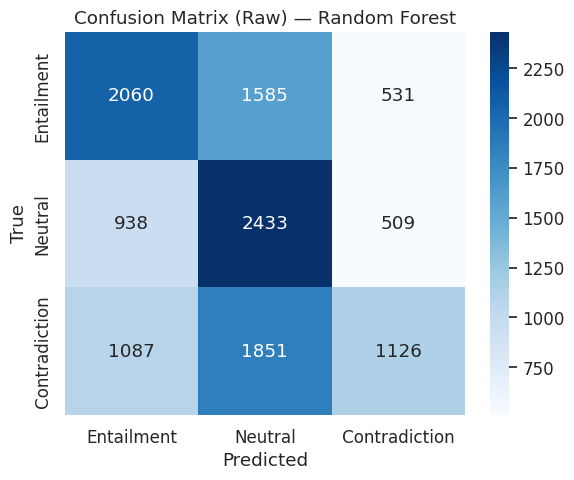

In [49]:

cm = confusion_matrix(y_train, best['oof_preds'])
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label, yticklabels=label, ax=ax)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title(f'Confusion Matrix (Raw) — {best_name}')
plt.tight_layout()
plt.show()


The Random Forest confusion matrix shows the exact distribution of the models predictions compared to the true labels across 12120 samples. The highest number of correct predictions belongs to the Neutral class with 2433 correctly classified samples. However 1851 samples from the Contradiction class and 1585 samples from the Entailment class were incorrectly predicted as Neutral indicating a strong bias of the model toward this class.The Entailment class also achieved a relatively stable performance with 2060 correct predictions although 938 Neutral samples and 1,087 Contradiction samples were incorrectly classified as Entailment. Furthermore the prediction results for the Contradiction class were the weakest with only 1126 true samples correctly identified. Overall the Random Forest model does not perform effectively in capturing the discriminative semantic features required for accurate classification

- Confusion Matrix Normalised — Random Forest

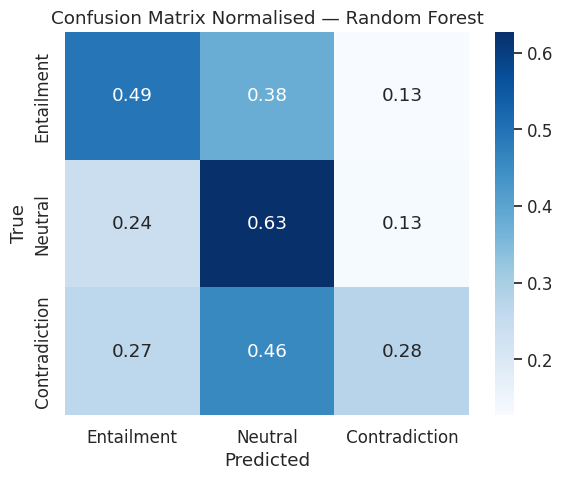

In [50]:
cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(cm_n, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=label, yticklabels=label, ax=ax)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title(f'Confusion Matrix Normalised — {best_name}')
plt.tight_layout()
plt.show()


According to the normalized results shown in this figure, the model achieved the highest Recall for the Neutral class at 63%. However, the 46% misclassification rate of Contradiction samples into the Neutral class indicates that this high recall is mainly caused by model bias rather than true semantic understanding.The Entailment class achieved a moderate Recall of 49% while 38% of its samples were incorrectly classified as Neutral. The weakest Recall belongs to the Contradiction class with only 28% indicating that more than 72% of contradiction samples are either missed or incorrectly classified by the model including 46% predicted as Neutral and 27% as Entailment. This normalized confusion matrix clearly demonstrates that the traditional model struggles to understand deeper semantic structures, particularly the distinction between the Neutral and Contradiction classes

# ROC Curves One vs Rest — Random Forest

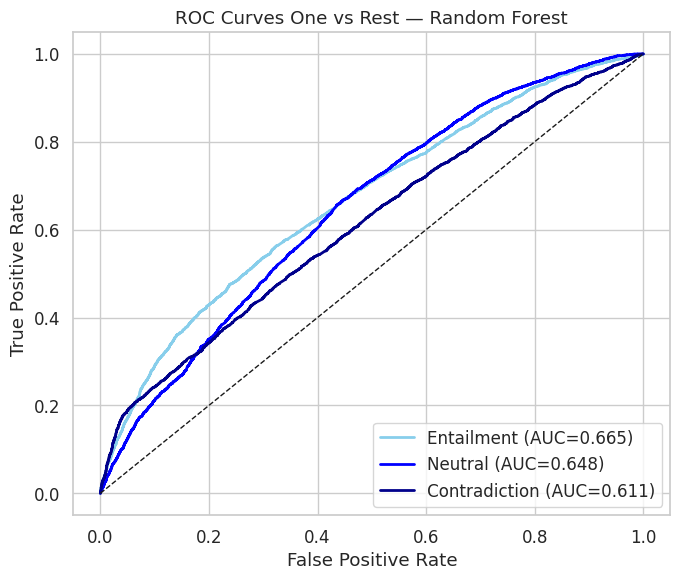

In [51]:
y_bin = pd.get_dummies(y_train).values
fig, ax = plt.subplots(figsize=(7,6))
for i, (lbl, col) in enumerate(zip(
        label, ['skyblue','blue','darkblue'])):
    fpr, tpr, _ = roc_curve(y_bin[:, i], best['oof_probs'][:, i])
    ax.plot(fpr, tpr, color=col, lw=2, label=f'{lbl} (AUC={auc(fpr,tpr):.3f})')
ax.plot([0,1],[0,1],'k--', lw=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title(f'ROC Curves One vs Rest — {best_name}')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

The ROC curve illustrates the discriminative ability of the Random Forest model across the different classes. The largest area under the curve (AUC) belongs to the Entailment class with a value of AUC = 0.665, indicating that the model is more successful in distinguishing this relationship from the other classes. The Neutral class ranks second with an AUC of 0.648, while the Contradiction class shows the weakest discriminative performance with the lowest value of AUC = 0.611. The clear positive deviation of all curves from the diagonal random baseline indicates that the model performs significantly better than chance for all classes. However, since the AUC values fall within the range of 0.61 to 0.66, the results suggest that although the model does not behave randomly, its discriminative capability remains at a moderate to relatively low level.

- Feature Importance — Random Forest

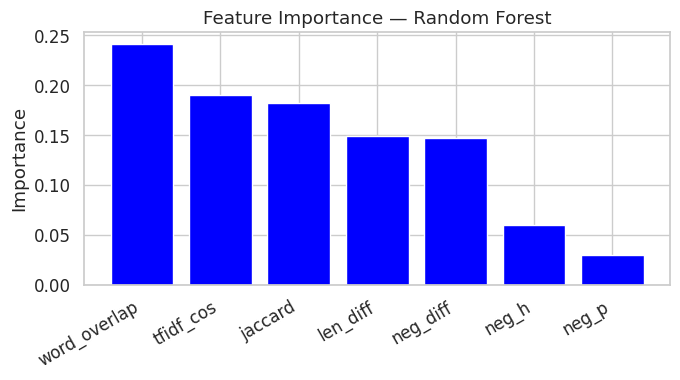

In [52]:
clf_step = best['model'].named_steps['clf']
if hasattr(clf_step, 'feature_importances_'):
    imp = clf_step.feature_importances_
    idx = np.argsort(imp)[::-1]
    fig, ax = plt.subplots(figsize=(7,4))
    ax.bar(range(len(FEATS)), imp[idx], color='blue', edgecolor='white')
    ax.set_xticks(range(len(FEATS)))
    ax.set_xticklabels([FEATS[i] for i in idx], rotation=30, ha='right')
    ax.set_title(f'Feature Importance — {best_name}')
    ax.set_ylabel('Importance')
    plt.tight_layout()
    plt.show()


According to this figure, the word_overlap feature ranks first with more than 24% importance, indicating that the models rely heavily on the surface-level overlap of words between the premise and the hypothesis. The tfidf_cos and jaccard features follow with approximately 19% and 18% importance, respectively, highlighting the significant role of low-level textual similarity measures in the models decision-making process.In addition, features related to text length differences and negation differences account for around 15% of the importance, while the direct presence of negation words in the premise or hypothesis has the lowest importance, contributing less than 6%. Overall, this distribution of feature importance suggests that the model relies more on statistical and surface-level lexical similarities rather than capturing deeper semantic meaning or logical structure between the sentences.

- Precision-Recall Curves — Random Forest

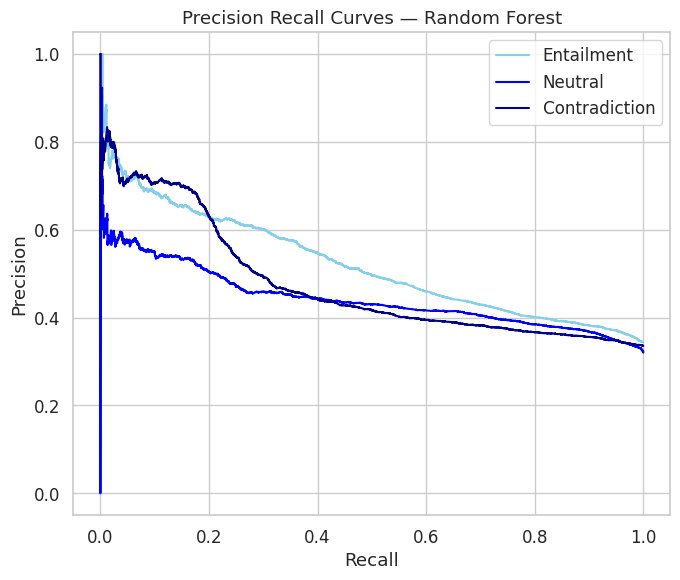

In [ ]:
fig, ax = plt.subplots(figsize=(7,6))

for i, (lbl, col) in enumerate(zip(label, ['skyblue','blue','darkblue'])):
    prec, rec, _ = precision_recall_curve(y_bin[:, i], best['oof_probs'][:, i])
    ax.plot(rec, prec, color=col, label=lbl)   

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title(f'Precision Recall Curves — {best_name}')
ax.legend()
plt.tight_layout()
plt.show()


This figure illustrates the trade-off between Precision and Recall for the three classes in the task. According to the plot, the Entailment class demonstrates the most stable behavior; as Recall increases, the decline in Precision is relatively small, indicating that the model maintains higher prediction quality for this class. In contrast, the Contradiction curve shows a sharp decrease at the beginning and remains below the other curves at higher Recall levels, which is consistent with the relatively low F1-score of 0.36 for this class. The Neutral class also exhibits a gradual decrease in Precision as Recall increases, although the decline is more stable compared to Contradiction. Although the dataset is balanced, the manually engineered features are not sufficiently capable of capturing subtle semantic distinctions between the classes

- Overall these results indicate that although the Random Forest model achieved the best performance among the traditional machine learning models, it still has significant limitations in understanding deep semantic relationships between sentences and its overall performance remains at a moderate level. This finding highlights the necessity of using deep learning and transformer-based models to improve semantic relationship detection in the NLI task


 Final Comparison: Transformer vs Traditional ML
              Model  Precision  Recall     F1    AUC
        XLM-RoBERTa     0.6957  0.6954 0.6953 0.8594
      Random Forest     0.4796  0.4658 0.4531 0.6413
            XGBoost     0.4627  0.4585 0.4513 0.6386
Logistic Regression     0.4604  0.4459 0.4319 0.6212
                SVM     0.4674  0.4453 0.4280 0.6205


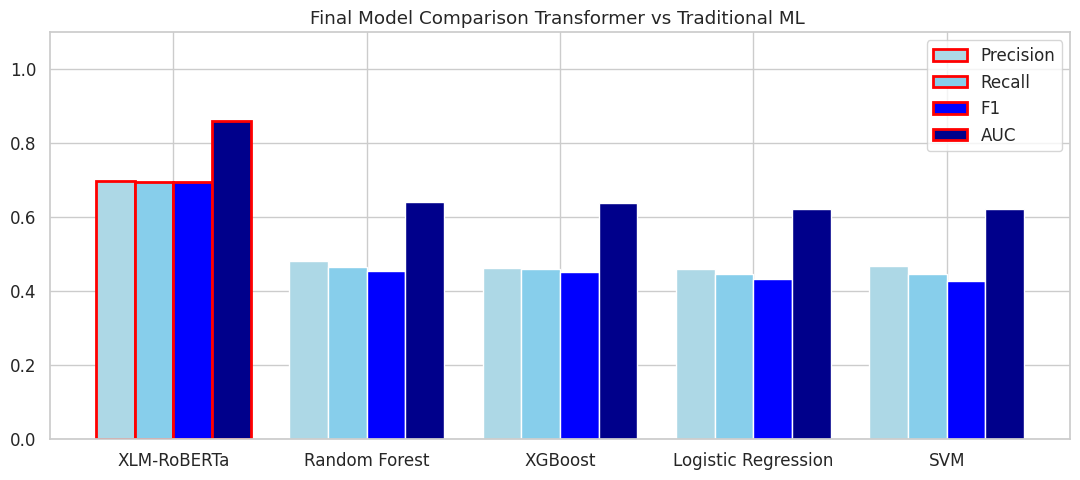

In [ ]:

xlmr_f1  = f1_score(val_true, val_preds, average='macro')
xlmr_pr  = precision_score(val_true, val_preds, average='macro')
xlmr_re  = recall_score(val_true, val_preds, average='macro')
xlmr_auc = roc_auc_score(
    pd.get_dummies(val_true).values, val_probs,
    multi_class='ovr', average='macro'
)

xlmr_row = pd.DataFrame([{
    'Model':     'XLM-RoBERTa',
    'Precision': xlmr_pr,
    'Recall':    xlmr_re,
    'F1':        xlmr_f1,
    'AUC':       xlmr_auc,
}])

final_comparison = pd.concat([comp, xlmr_row], ignore_index=True)\
                     .sort_values('F1', ascending=False)\
                     .reset_index(drop=True)

print('\n Final Comparison: Transformer vs Traditional ML')
print(final_comparison.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(final_comparison))
w = 0.2
blue_shades = ['lightblue', 'skyblue', 'blue', 'darkblue']

for i, (metric, color) in enumerate(zip(['Precision', 'Recall', 'F1', 'AUC'], blue_shades)):
    bars = ax.bar(x + i * w, final_comparison[metric], w, label=metric, color=color)


xlmr_idx = final_comparison[final_comparison['Model'] == 'XLM-RoBERTa'].index[0]
for i in range(4):
    ax.patches[xlmr_idx + i * len(final_comparison)].set_edgecolor('red')
    ax.patches[xlmr_idx + i * len(final_comparison)].set_linewidth(2)

ax.set_xticks(x + w * 1.5)
ax.set_xticklabels(final_comparison['Model'])
ax.set_ylim(0, 1.1)
ax.set_title('Final Model Comparison Transformer vs Traditional ML ')
ax.legend()
plt.tight_layout()
plt.show()

Therefore, the comparison of models demonstrates that the XLM-RoBERTa-base model, with a Macro F1 score of 0.695 and an AUC of 0.859, achieved significantly stronger performance than the Random Forest model, which obtained an F1 score of 0.45. This 53% performance improvement highlights the fundamental difference between the two approaches. While classical machine learning models rely mainly on statistical and surface-level lexical features, such as word overlap, and therefore face limitations in capturing complex logical relationships, transformer-based models leverage contextual semantic representations and multilingual knowledge to understand abstract relationships without the need for handcrafted linguistic feature engineering. However, the confusion matrix analysis indicates that the transformer model still experiences some difficulty in distinguishing the Neutral class, mainly due to the inherent semantic ambiguity of this category and its surface similarity to the Entailment class. Ultimately, despite challenges such as higher computational cost and the requirement for GPU resources, the findings suggest that the use of deep learning architectures and transformer-based models is essential for achieving satisfactory semantic accuracy in multilingual NLI tasks.
